[1/8] DATA SCIENTIST LOG: Ingesting Full Sensor Array + Temporal Features...
[DATA] Total samples after filtering: 2564
[DATA] Training samples (85%): 2179
[DATA] Test samples (10%): 256
[DATA] Calibration samples (5%): 129
[DATA] Number of input features: 26
[2/8] DATA SCIENTIST LOG: Training Neuro-Residual Core...
   Epoch 30/150 - Train Loss: 0.1054 | Val Loss: 0.1629
   Epoch 60/150 - Train Loss: 0.0742 | Val Loss: 0.1275
   Epoch 90/150 - Train Loss: 0.0592 | Val Loss: 0.1013
   Epoch 120/150 - Train Loss: 0.0535 | Val Loss: 0.0824
   Epoch 150/150 - Train Loss: 0.0477 | Val Loss: 0.0831
[3/8] DATA SCIENTIST LOG: Running Inference...
[4/8] DATA SCIENTIST LOG: Computing Bayesian Uncertainty...
[5/8] DATA SCIENTIST LOG: Rendering Individual Figures...


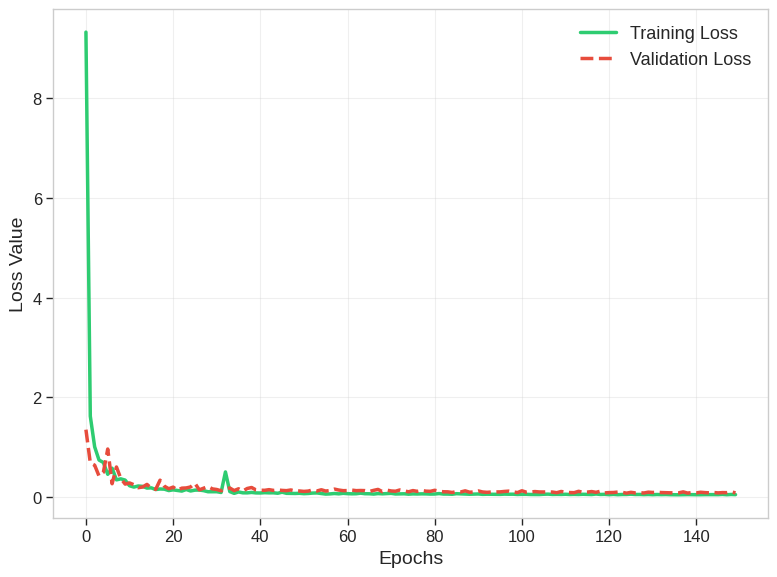

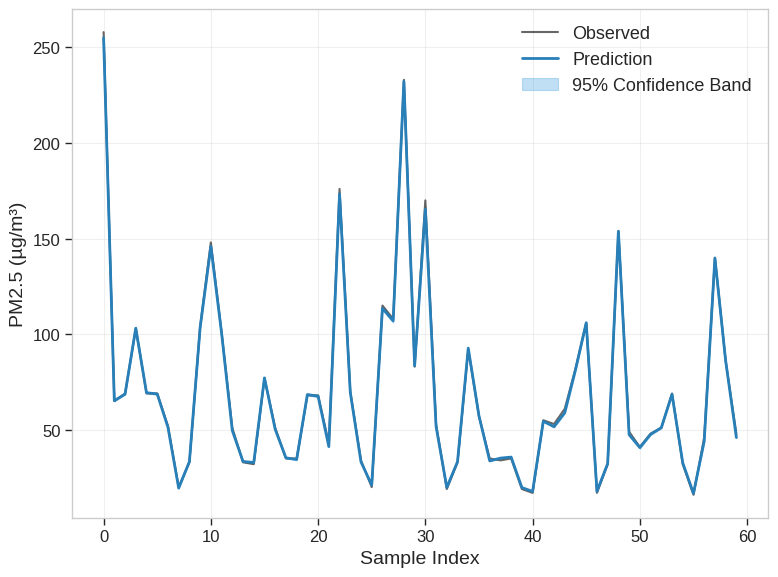

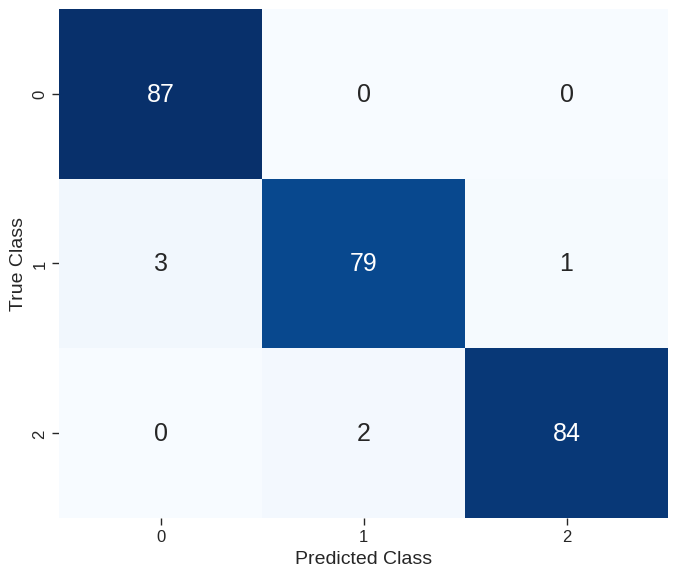

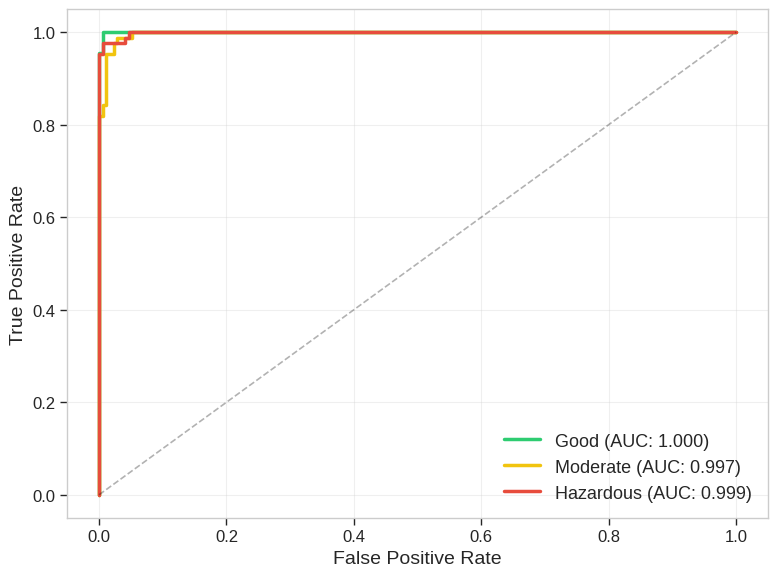

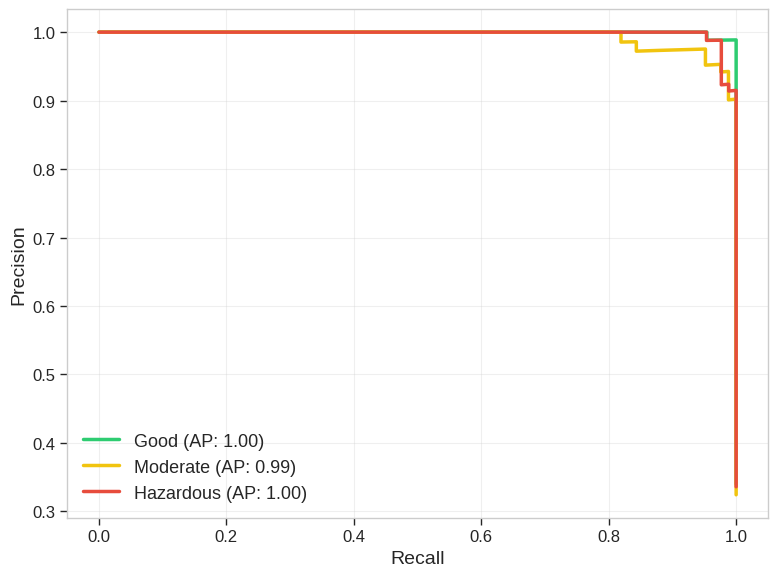

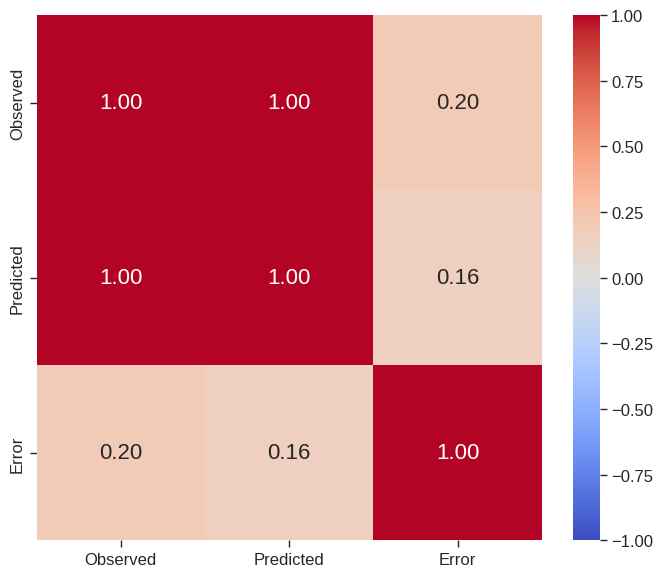

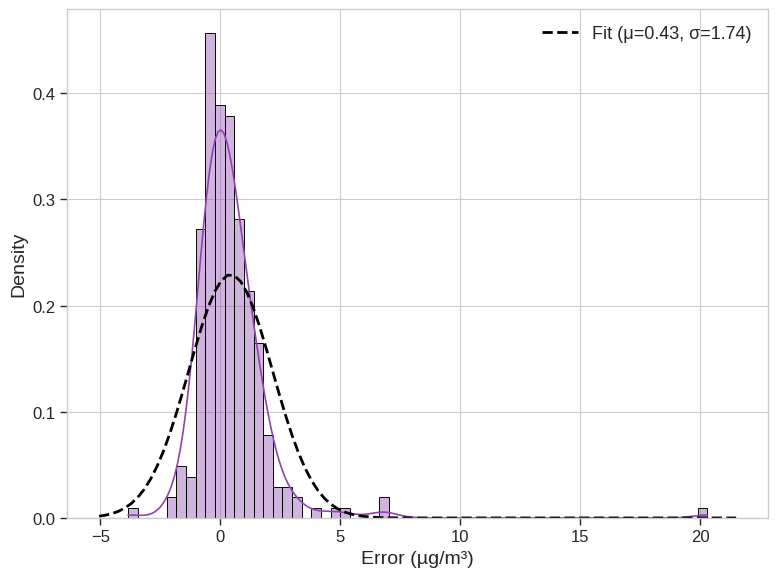

[6/8] DATA SCIENTIST LOG: Running XAI...


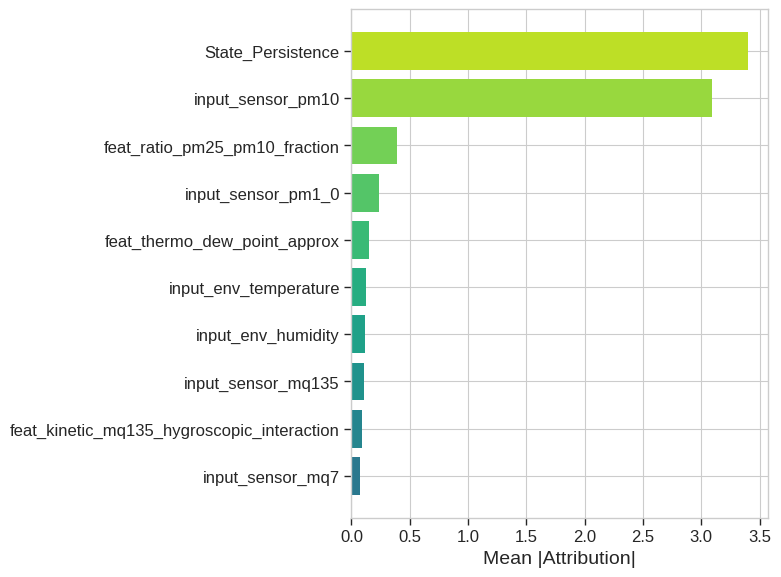

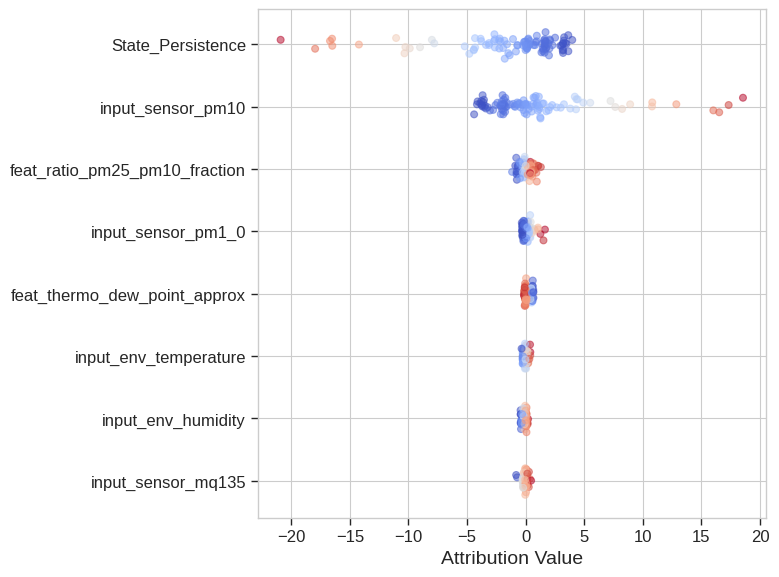

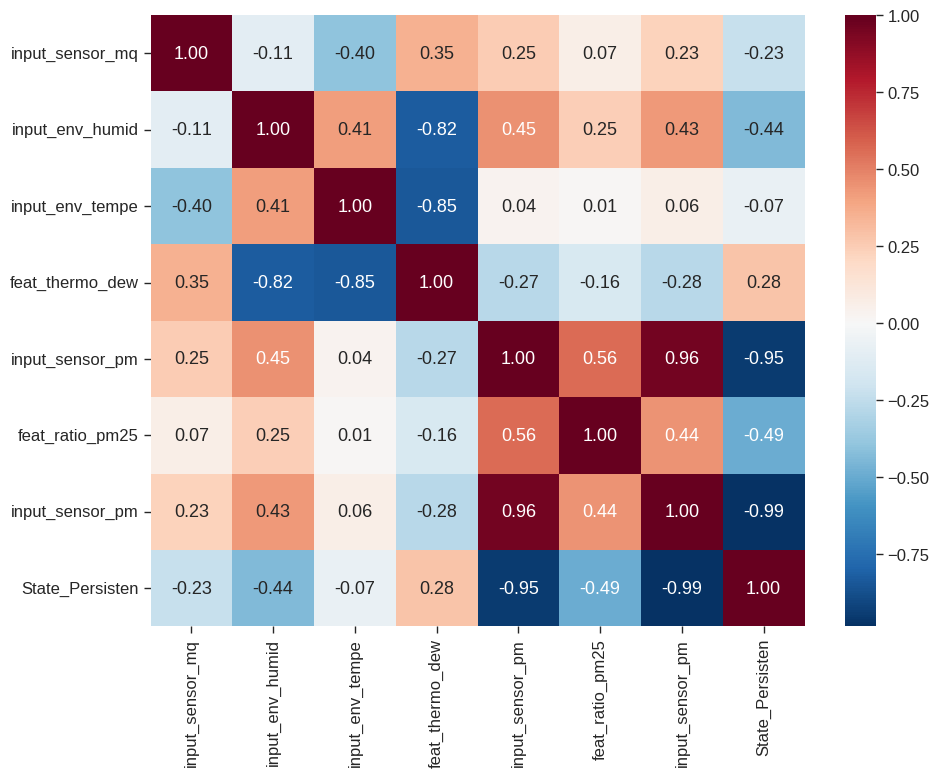

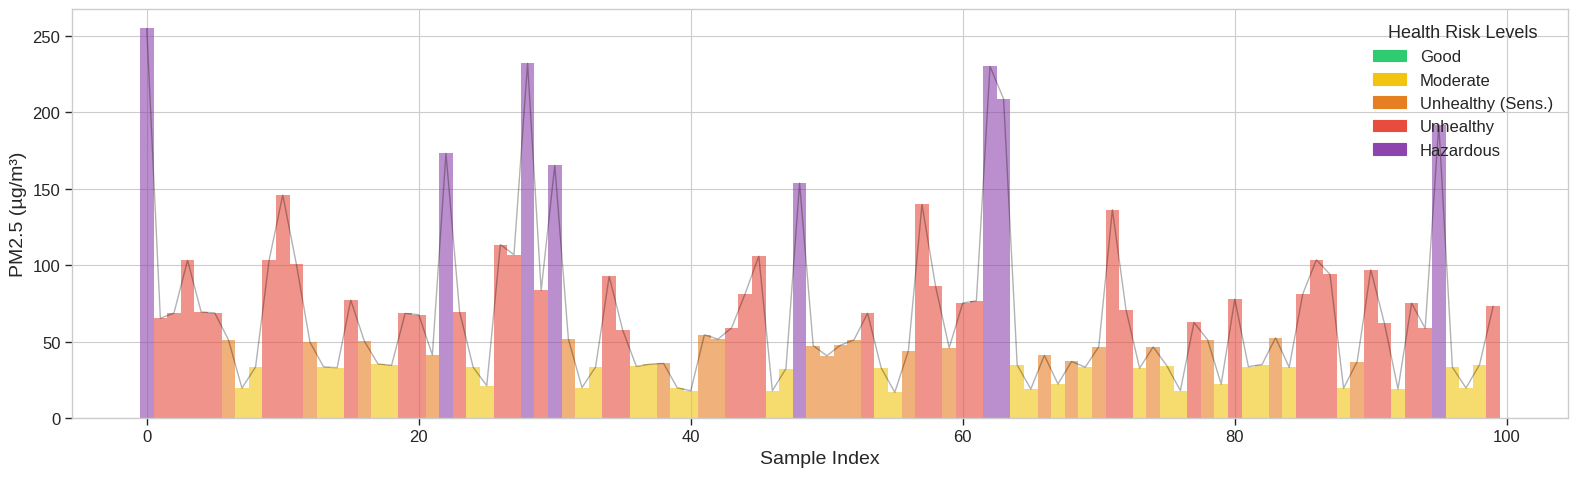

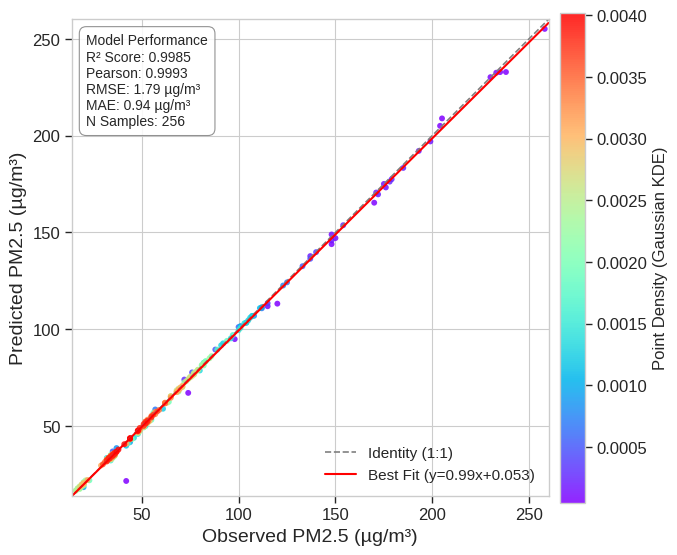

NEUROAQ V4.0 RESULTS | Best Val Loss: 0.0773 | Final R²: 0.9985
✓ Best Model Saved: /content/drive/MyDrive/Colab Notebooks/ICCA-Revision/NeuroAQ_Models/best_neuroaq_model.pt
✓ Fig 1a: Loss Curve
✓ Fig 1b: Bayesian Prediction
✓ Fig 1c: Confusion Matrix
✓ Fig 1d: ROC Curves
✓ Fig 2a: Precision-Recall
✓ Fig 2b: Pearson Correlation
✓ Fig 2c: Error Distribution
✓ Fig 3a: Feature Importance
✓ Fig 3b: Feature Impact
✓ Fig 3c: Feature Interaction
✓ Fig 4: Health Alerts
✓ Fig 5: R² Plot (Professional)


In [ ]:
# ARCHITECTURE: Hierarchical Multi-Task Residual Transformer (H-MTRT)

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from sklearn.preprocessing import StandardScaler, RobustScaler, label_binarize
from sklearn.metrics import (mean_squared_error, r2_score, roc_curve, auc,
                             confusion_matrix, accuracy_score, f1_score,
                             precision_recall_curve, average_precision_score)
from scipy.stats import pearsonr, norm
import random
import warnings
import os
import sys
from datetime import datetime

# =============================================================================
# 1. SETUP & REPRODUCIBILITY
# =============================================================================
warnings.filterwarnings("ignore")
# Use a professional style for plots
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_context("paper", font_scale=1.8)
plt.rcParams.update({
    'font.size': 14,
    'axes.titlesize': 16,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 12,
    'figure.titlesize': 20,
    'savefig.dpi': 400,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1,
})
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(42)

# =============================================================================
# 2. ENHANCED DATA INGESTION
# =============================================================================
RAW_SOURCE_PATH = '/content/drive/MyDrive/Colab Notebooks/ICCA-Revision/synairdataset.csv'

def get_full_spectrum_data(filepath):
    print("[1/8] DATA SCIENTIST LOG: Ingesting Full Sensor Array + Temporal Features...")
    if not os.path.exists(filepath): return None

    df = pd.read_csv(filepath, parse_dates=['timestamp_iso'], low_memory=False)
    if 'timestamp_iso' not in df.columns and 'datetime' in df.columns:
         df['timestamp_iso'] = pd.to_datetime(df['datetime'])

    for col in df.columns:
        if col not in ['timestamp_iso', 'key', 'meta_city']:
            df[col] = pd.to_numeric(df[col], errors='coerce')

    if 'timestamp_iso' in df.columns:
        df['hour'] = df['timestamp_iso'].dt.hour
        df['day_of_week'] = df['timestamp_iso'].dt.dayofweek
        df['is_weekend'] = (df['day_of_week'] >= 5).astype(float)
        temporal_cols = ['hour', 'day_of_week', 'is_weekend']
    else:
        temporal_cols = []

    df = df.ffill().bfill().fillna(0)
    sensor_cols = [c for c in df.columns if 'input_' in c or 'feat_' in c]
    input_cols = [c for c in sensor_cols if c != 'input_sensor_pm2_5']

    df['target_raw'] = df['input_sensor_pm2_5']
    df['prev_target'] = df['target_raw'].shift(1).bfill()
    df['diff_target'] = df['target_raw'] - df['prev_target']
    df = df[df['diff_target'].abs() < 50]

    X_raw = df[input_cols].values
    prev_col = df['prev_target'].values.reshape(-1, 1)

    if temporal_cols:
        X_combined = np.hstack([X_raw, prev_col, df[temporal_cols].values])
        feat_labels = input_cols + ['State_Persistence'] + temporal_cols
    else:
        X_combined = np.hstack([X_raw, prev_col])
        feat_labels = input_cols + ['State_Persistence']

    q33, q66 = df['target_raw'].quantile(0.33), df['target_raw'].quantile(0.66)
    def get_class(val): return 0 if val <= q33 else (1 if val <= q66 else 2)
    Y_cls = np.array([get_class(v) for v in df['target_raw'].values])

    sc_x, sc_y = RobustScaler(), StandardScaler()
    X = sc_x.fit_transform(X_combined)
    Y_reg_scaled = sc_y.fit_transform(df[['diff_target']].values)

    # Input Clamping for stability
    X = np.clip(X, -10, 10)

    return X, Y_reg_scaled, Y_cls, df['prev_target'].values, df['target_raw'].values, sc_y, feat_labels, sc_x

# =============================================================================
# 3. MODEL ARCHITECTURE
# =============================================================================
class NeuroResidualBlock(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(dim, dim), nn.LayerNorm(dim), nn.GELU(),
            nn.Linear(dim, dim), nn.LayerNorm(dim)
        )
    def forward(self, x): return x + self.fc(x)

class NeuroAQ(nn.Module):
    def __init__(self, in_dim):
        super().__init__()
        self.input_proj = nn.Sequential(nn.Linear(in_dim, 512), nn.GELU())
        self.body = nn.Sequential(
            NeuroResidualBlock(512), NeuroResidualBlock(512), nn.Dropout(0.1)
        )
        self.reg_head = nn.Linear(512, 1)
        self.cls_head = nn.Linear(512, 3)
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                if m.bias is not None: nn.init.zeros_(m.bias)

    def forward(self, x):
        feat = self.body(self.input_proj(x))
        return self.reg_head(feat), self.cls_head(feat)

    def predict_with_uncertainty(self, x, n_samples=50):
        self.train()
        preds_reg, preds_cls = [], []
        for _ in range(n_samples):
            with torch.no_grad():
                reg_out, cls_out = self(x)
                preds_reg.append(reg_out.cpu().numpy())
                preds_cls.append(F.softmax(cls_out, dim=1).cpu().numpy())
        return (np.mean(preds_reg, axis=0), np.std(preds_reg, axis=0),
                np.mean(preds_cls, axis=0), np.std(preds_cls, axis=0))

# =============================================================================
# 4. WEAKNESS-TO-STRENGTH (LOSS) & UTILS
# =============================================================================
class AdaptiveFocalLoss(nn.Module):
    def __init__(self, gamma=2.0, alpha=1.0):
        super().__init__()
        self.gamma = gamma; self.alpha = alpha
    def forward(self, inputs, targets):
        ce_loss = F.cross_entropy(inputs, targets, reduction='none')
        pt = torch.exp(-ce_loss)
        return (self.alpha * (1 - pt) ** self.gamma * ce_loss).mean()

def compute_adaptive_reg_loss(pred, target):
    raw_loss = (pred - target) ** 2
    difficulty_weight = 1 + torch.tanh(torch.abs(pred - target).detach())
    return (raw_loss * difficulty_weight).mean()

def generate_health_alert(pm25_value):
    if pm25_value <= 12.0: return "Good", "#2ecc71"
    elif pm25_value <= 35.4: return "Moderate", "#f1c40f"
    elif pm25_value <= 55.4: return "Unhealthy (Sens.)", "#e67e22"
    elif pm25_value <= 150.4: return "Unhealthy", "#e74c3c"
    else: return "Hazardous", "#8e44ad"

# =============================================================================
# 5. TRAINING WORKFLOW
# =============================================================================
print("="*80)
data = get_full_spectrum_data(RAW_SOURCE_PATH)
if data is None: sys.exit("ERROR: Check data path.")

X, Y_reg, Y_cls, Prev, TrueVal, SCALER_Y, feat_labels, SCALER_X = data

idx = np.arange(len(X))
np.random.shuffle(idx)
split, cal_split = int(len(X) * 0.85), int(len(X) * 0.95)

# Log dataset sample sizes for manuscript reporting
print(f"[DATA] Total samples after filtering: {len(X)}")
print(f"[DATA] Training samples (85%): {split}")
print(f"[DATA] Test samples (10%): {cal_split - split}")
print(f"[DATA] Calibration samples (5%): {len(X) - cal_split}")
print(f"[DATA] Number of input features: {X.shape[1]}")
tr, te, ca = idx[:split], idx[split:cal_split], idx[cal_split:]

model = NeuroAQ(X.shape[1]).to(DEVICE)
opt = torch.optim.AdamW(model.parameters(), lr=0.0005, weight_decay=1e-5)
focal_criterion = AdaptiveFocalLoss(gamma=2.0).to(DEVICE)

print("[2/8] DATA SCIENTIST LOG: Training Neuro-Residual Core...")
train_ldr = DataLoader(TensorDataset(torch.Tensor(X[tr]), torch.Tensor(Y_reg[tr]), torch.LongTensor(Y_cls[tr])), batch_size=32, shuffle=True)
vx, vr, vc = torch.Tensor(X[te]).to(DEVICE), torch.Tensor(Y_reg[te]).to(DEVICE), torch.LongTensor(Y_cls[te]).to(DEVICE)

loss_history = {'train': [], 'val': []}
EPOCHS = 150
best_val_loss = float('inf')
save_dir = '/content/drive/MyDrive/Colab Notebooks/ICCA-Revision/NeuroAQ_Models'
os.makedirs(save_dir, exist_ok=True)

for epoch in range(EPOCHS):
    model.train()
    batch_losses = []
    for bx, br, bc in train_ldr:
        bx, br, bc = bx.to(DEVICE), br.to(DEVICE), bc.to(DEVICE)
        pr, pc = model(bx)
        loss = compute_adaptive_reg_loss(pr, br) + 0.6 * focal_criterion(pc, bc)
        opt.zero_grad(); loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        opt.step()
        batch_losses.append(loss.item())

    model.eval()
    with torch.no_grad():
        vpr, vpc = model(vx)
        v_loss = F.mse_loss(vpr, vr) + 0.6 * F.cross_entropy(vpc, vc)

        # Save Best Model Logic
        if v_loss < best_val_loss:
            best_val_loss = v_loss
            torch.save(model.state_dict(), f"{save_dir}/best_neuroaq_model.pt")

    loss_history['train'].append(np.mean(batch_losses))
    loss_history['val'].append(v_loss.item())

    if (epoch + 1) % 30 == 0:
        print(f"   Epoch {epoch+1}/{EPOCHS} - Train Loss: {np.mean(batch_losses):.4f} | Val Loss: {v_loss.item():.4f}")

# =============================================================================
# 6. INFERENCE & METRICS
# =============================================================================
print("[3/8] DATA SCIENTIST LOG: Running Inference...")
model.load_state_dict(torch.load(f"{save_dir}/best_neuroaq_model.pt")) # Load best model
model.eval()
with torch.no_grad():
    tx = torch.Tensor(X[te]).to(DEVICE)
    pr, pc = model(tx)
    y_pred = Prev[te] + SCALER_Y.inverse_transform(pr.cpu().numpy()).flatten()
    y_true = TrueVal[te]
    probs = F.softmax(pc, dim=1).cpu().numpy()
    preds = np.argmax(probs, axis=1)

print("[4/8] DATA SCIENTIST LOG: Computing Bayesian Uncertainty...")
tx_sub = torch.Tensor(X[te[:200]]).to(DEVICE) # Taking 200 samples for visualization
m_reg, s_reg, m_cls, s_cls = model.predict_with_uncertainty(tx_sub)
y_pred_unc = Prev[te[:200]] + SCALER_Y.inverse_transform(m_reg).flatten()
unc_vals = SCALER_Y.scale_[0] * s_reg.flatten()
unc_vals = np.maximum(unc_vals, 0.1)
y_true_unc = TrueVal[te[:200]]

# Metrics
final_r2 = r2_score(y_true, y_pred)
final_acc = accuracy_score(Y_cls[te], preds)
final_auc = auc(roc_curve(label_binarize(Y_cls[te], classes=[0,1,2]).ravel(), probs.ravel())[0],
                roc_curve(label_binarize(Y_cls[te], classes=[0,1,2]).ravel(), probs.ravel())[1])

# =============================================================================
# 7. INDIVIDUAL FIGURE GENERATION (One image per plot, no titles)
# =============================================================================
print("[5/8] DATA SCIENTIST LOG: Rendering Individual Figures...")

colors = ['#2ecc71', '#f1c40f', '#e74c3c']
classes = ['Good', 'Moderate', 'Hazardous']

# --- Figure 1a: Training vs Validation Loss Convergence ---
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(loss_history['train'], label='Training Loss', color='#2ecc71', linewidth=2.5)
ax.plot(loss_history['val'], label='Validation Loss', color='#e74c3c', linewidth=2.5, linestyle='--')
ax.set_xlabel('Epochs', fontsize=14); ax.set_ylabel('Loss Value', fontsize=14)
ax.legend(fontsize=13); ax.grid(True, alpha=0.3)
ax.tick_params(axis='both', labelsize=12)
plt.tight_layout()
plt.savefig(f"{save_dir}/Fig_1a_LossCurve.png", dpi=400)
plt.show()

# --- Figure 1b: Bayesian Prediction & Uncertainty Intervals ---
fig, ax = plt.subplots(figsize=(8, 6))
subset_viz = 60
x_idx = range(subset_viz)
ax.plot(x_idx, y_true_unc[:subset_viz], 'k-', label='Observed', alpha=0.6, linewidth=1.5)
ax.plot(x_idx, y_pred_unc[:subset_viz], color='#2980b9', label='Prediction', linewidth=2)
lower = y_pred_unc[:subset_viz] - 2 * unc_vals[:subset_viz]
upper = y_pred_unc[:subset_viz] + 2 * unc_vals[:subset_viz]
ax.fill_between(x_idx, lower, upper, color='#3498db', alpha=0.3, label='95% Confidence Band')
ax.set_xlabel('Sample Index', fontsize=14); ax.set_ylabel('PM2.5 (µg/m³)', fontsize=14)
ax.legend(fontsize=13); ax.grid(True, alpha=0.3)
ax.tick_params(axis='both', labelsize=12)
plt.tight_layout()
plt.savefig(f"{save_dir}/Fig_1b_BayesianPrediction.png", dpi=400)
plt.show()

# --- Figure 1c: Confusion Matrix ---
fig, ax = plt.subplots(figsize=(7, 6))
cm = confusion_matrix(Y_cls[te], preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False, annot_kws={"size": 18})
ax.set_xlabel('Predicted Class', fontsize=14); ax.set_ylabel('True Class', fontsize=14)
ax.tick_params(axis='both', labelsize=12)
plt.tight_layout()
plt.savefig(f"{save_dir}/Fig_1c_ConfusionMatrix.png", dpi=400)
plt.show()

# --- Figure 1d: Multi-Class ROC Curves ---
fig, ax = plt.subplots(figsize=(8, 6))
for i in range(3):
    fpr, tpr, _ = roc_curve(label_binarize(Y_cls[te], classes=[0,1,2])[:, i], probs[:, i])
    ax.plot(fpr, tpr, color=colors[i], lw=2.5, label=f'{classes[i]} (AUC: {auc(fpr, tpr):.3f})')
ax.plot([0, 1], [0, 1], 'k--', alpha=0.3)
ax.set_xlabel('False Positive Rate', fontsize=14); ax.set_ylabel('True Positive Rate', fontsize=14)
ax.legend(loc='lower right', fontsize=13); ax.grid(True, alpha=0.3)
ax.tick_params(axis='both', labelsize=12)
plt.tight_layout()
plt.savefig(f"{save_dir}/Fig_1d_ROC.png", dpi=400)
plt.show()

# --- Figure 2a: Precision-Recall Curves ---
fig, ax = plt.subplots(figsize=(8, 6))
for i in range(3):
    prec, rec, _ = precision_recall_curve(label_binarize(Y_cls[te], classes=[0,1,2])[:, i], probs[:, i])
    avg_prec = average_precision_score(label_binarize(Y_cls[te], classes=[0,1,2])[:, i], probs[:, i])
    ax.plot(rec, prec, lw=2.5, color=colors[i], label=f'{classes[i]} (AP: {avg_prec:.2f})')
ax.set_xlabel('Recall', fontsize=14); ax.set_ylabel('Precision', fontsize=14)
ax.legend(fontsize=13); ax.grid(True, alpha=0.3)
ax.tick_params(axis='both', labelsize=12)
plt.tight_layout()
plt.savefig(f"{save_dir}/Fig_2a_PrecisionRecall.png", dpi=400)
plt.show()

# --- Figure 2b: Pearson Correlation Heatmap ---
fig, ax = plt.subplots(figsize=(7, 6))
corr_df = pd.DataFrame({'Observed': y_true[:500], 'Predicted': y_pred[:500], 'Error': (y_true-y_pred)[:500]})
sns.heatmap(corr_df.corr(), annot=True, cmap='coolwarm', vmin=-1, vmax=1, ax=ax, fmt='.2f',
            annot_kws={"size": 16})
ax.tick_params(axis='both', labelsize=12)
plt.tight_layout()
plt.savefig(f"{save_dir}/Fig_2b_PearsonCorrelation.png", dpi=400)
plt.show()

# --- Figure 2c: Error Distribution ---
fig, ax = plt.subplots(figsize=(8, 6))
errors = y_true - y_pred
sns.histplot(errors, kde=True, color='#8e44ad', ax=ax, stat='density', alpha=0.4)
mu, std = norm.fit(errors)
xmin, xmax = ax.get_xlim()
x_pdf = np.linspace(xmin, xmax, 100)
p_pdf = norm.pdf(x_pdf, mu, std)
ax.plot(x_pdf, p_pdf, 'k--', linewidth=2, label=f'Fit (μ={mu:.2f}, σ={std:.2f})')
ax.set_xlabel('Error (µg/m³)', fontsize=14); ax.set_ylabel('Density', fontsize=14)
ax.legend(fontsize=13)
ax.tick_params(axis='both', labelsize=12)
plt.tight_layout()
plt.savefig(f"{save_dir}/Fig_2c_ErrorDistribution.png", dpi=400)
plt.show()

# --- DASHBOARD 3: XAI & EXPLAINABILITY ---
# Integrated Gradients Calculation (simplified for viz)
def integrated_gradients_attribution(model, input_tensor, baseline=None, n_steps=50):
    model.eval()
    if baseline is None: baseline = torch.zeros_like(input_tensor)
    alphas = torch.linspace(0, 1, n_steps).to(input_tensor.device)
    interpolated = baseline.unsqueeze(0) + alphas.view(-1, 1, 1) * (input_tensor.unsqueeze(0) - baseline.unsqueeze(0))
    attributions = []
    for i in range(n_steps):
        inp = interpolated[i].requires_grad_(True)
        out, _ = model(inp)
        out.sum().backward()
        attributions.append(inp.grad.detach().cpu().numpy())
    return (input_tensor - baseline).cpu().numpy() * np.mean(attributions, axis=0)

print("[6/8] DATA SCIENTIST LOG: Running XAI...")
test_xai = torch.Tensor(X[te[:100]]).to(DEVICE)
attrs = integrated_gradients_attribution(model, test_xai)
mean_attr = np.mean(np.abs(attrs), axis=0)
top_idx = np.argsort(mean_attr)[-10:]

# --- Figure 3a: Global Feature Importance ---
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(range(10), mean_attr[top_idx], color=plt.cm.viridis(np.linspace(0.4, 0.9, 10)))
ax.set_yticks(range(10)); ax.set_yticklabels([feat_labels[i] for i in top_idx], fontsize=12)
ax.set_xlabel('Mean |Attribution|', fontsize=14)
ax.tick_params(axis='x', labelsize=12)
plt.tight_layout()
plt.savefig(f"{save_dir}/Fig_3a_FeatureImportance.png", dpi=400)
plt.show()

# --- Figure 3b: Feature Impact Distribution ---
fig, ax = plt.subplots(figsize=(8, 6))
for i, idx in enumerate(top_idx[-8:]):
    ax.scatter(attrs[:, idx], np.random.normal(i, 0.08, len(attrs)), alpha=0.5, s=25, c=X[te[:100], idx], cmap='coolwarm')
ax.set_yticks(range(8)); ax.set_yticklabels([feat_labels[i] for i in top_idx[-8:]], fontsize=12)
ax.set_xlabel('Attribution Value', fontsize=14)
ax.tick_params(axis='x', labelsize=12)
plt.tight_layout()
plt.savefig(f"{save_dir}/Fig_3b_FeatureImpact.png", dpi=400)
plt.show()

# --- Figure 3c: Feature Interaction Matrix ---
fig, ax = plt.subplots(figsize=(10, 8))
top_8 = top_idx[-8:]
inter_mat = np.zeros((8, 8))
for i in range(8):
    for j in range(8): inter_mat[i, j] = np.corrcoef(attrs[:, top_8[i]], attrs[:, top_8[j]])[0, 1]
sns.heatmap(inter_mat, xticklabels=[feat_labels[i][:15] for i in top_8], yticklabels=[feat_labels[i][:15] for i in top_8],
            cmap='RdBu_r', center=0, annot=True, fmt='.2f', ax=ax,
            annot_kws={"size": 13})
ax.tick_params(axis='both', labelsize=12)
plt.tight_layout()
plt.savefig(f"{save_dir}/Fig_3c_FeatureInteraction.png", dpi=400)
plt.show()

# --- Figure 4: Health Alert Timeline ---
alerts = [generate_health_alert(val) for val in y_pred_unc[:100]]
alert_colors = [a[1] for a in alerts]
fig, ax = plt.subplots(figsize=(16, 5))
ax.bar(range(100), y_pred_unc[:100], color=alert_colors, alpha=0.6, width=1.0)
ax.plot(range(100), y_pred_unc[:100], color='black', alpha=0.3, linewidth=1)
ax.set_ylabel('PM2.5 (µg/m³)', fontsize=14)
ax.set_xlabel('Sample Index', fontsize=14)
ax.tick_params(axis='both', labelsize=12)
patches = [mpatches.Patch(color=c, label=l) for l, c in
           [generate_health_alert(10), generate_health_alert(30), generate_health_alert(50),
            generate_health_alert(100), generate_health_alert(200)]]
ax.legend(handles=patches, loc='upper right', title="Health Risk Levels", fontsize=12, title_fontsize=13)
plt.tight_layout()
plt.savefig(f"{save_dir}/Fig_4_HealthAlerts.png", dpi=400)
plt.show()

# --- Figure 5: Professional R² Plot ---
from scipy.stats import gaussian_kde
fig, ax = plt.subplots(figsize=(7, 7))
xy = np.vstack([y_true, y_pred])
density = gaussian_kde(xy)(xy)
sort_idx = density.argsort()
x_s, y_s, d_s = y_true[sort_idx], y_pred[sort_idx], density[sort_idx]
scatter = ax.scatter(x_s, y_s, c=d_s, cmap='rainbow', s=18, edgecolors='none', alpha=0.85)
cbar = plt.colorbar(scatter, ax=ax, shrink=0.75, pad=0.02)
cbar.set_label('Point Density (Gaussian KDE)', fontsize=12)
lims = [min(y_true.min(), y_pred.min()) - 2, max(y_true.max(), y_pred.max()) + 2]
ax.plot(lims, lims, '--', color='gray', linewidth=1.2, label='Identity (1:1)')
slope, intercept = np.polyfit(y_true, y_pred, 1)
x_fit = np.linspace(lims[0], lims[1], 100)
ax.plot(x_fit, slope * x_fit + intercept, '-', color='red', linewidth=1.5,
        label=f'Best Fit (y={slope:.2f}x+{intercept:.3f})')
rmse_val = np.sqrt(mean_squared_error(y_true, y_pred))
mae_val = np.mean(np.abs(y_true - y_pred))
pearson_val = np.corrcoef(y_true, y_pred)[0, 1]
n_samples = len(y_true)
textstr = (f'Model Performance\n'
           f'R² Score: {final_r2:.4f}\n'
           f'Pearson: {pearson_val:.4f}\n'
           f'RMSE: {rmse_val:.2f} µg/m³\n'
           f'MAE: {mae_val:.2f} µg/m³\n'
           f'N Samples: {n_samples}')
props = dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.85, edgecolor='gray')
ax.text(0.03, 0.97, textstr, transform=ax.transAxes, fontsize=10,
        verticalalignment='top', bbox=props)
ax.set_xlabel('Observed PM2.5 (µg/m³)', fontsize=14)
ax.set_ylabel('Predicted PM2.5 (µg/m³)', fontsize=14)
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.legend(loc='lower right', fontsize=11)
ax.tick_params(labelsize=12)
ax.set_aspect('equal')
plt.tight_layout()
plt.savefig(f"{save_dir}/NeuroAQ_Professional_R2_Plot.png", dpi=400)
plt.show()

print("="*80)
print(f"NEUROAQ V4.0 RESULTS | Best Val Loss: {best_val_loss:.4f} | Final R²: {final_r2:.4f}")
print(f"✓ Best Model Saved: {save_dir}/best_neuroaq_model.pt")
print("✓ Fig 1a: Loss Curve")
print("✓ Fig 1b: Bayesian Prediction")
print("✓ Fig 1c: Confusion Matrix")
print("✓ Fig 1d: ROC Curves")
print("✓ Fig 2a: Precision-Recall")
print("✓ Fig 2b: Pearson Correlation")
print("✓ Fig 2c: Error Distribution")
print("✓ Fig 3a: Feature Importance")
print("✓ Fig 3b: Feature Impact")
print("✓ Fig 3c: Feature Interaction")
print("✓ Fig 4: Health Alerts")
print("✓ Fig 5: R² Plot (Professional)")
print("="*80)